In [ ]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import sys
from scipy.stats import spearmanr
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = 'glpk'

In [ ]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

gem2seed = pd.read_csv('../../Expression_datasets/model_reaction_to_seed_reaction_mapping.csv')
Ecoli = cobra.io.load_json_model('../../Expression_datasets/palsson_nc/iML1515.json')

In [ ]:
from dataclasses import dataclass

@dataclass
class Sample:
    E: np.ndarray      # shape (n,)
    Y: float

with open('../../FBA_solution/all_samples_ecoli_wo_normalize.pkl', 'rb') as f:
    data = pickle.load(f)
samples1 = data['samples1']
samples2 = data['samples2']
samples3 = data['samples3']
samples4 = data['samples4']
samples = samples1 + samples2 + samples3 + samples4

Node 0: Spearman correlation = 0.9747, p-value = 2.4976e-79
Node 1: Spearman correlation = 0.0219, p-value = 8.1131e-01
Node 2: Spearman correlation = 0.1506, p-value = 9.9169e-02
Node 3: Spearman correlation = -0.4136, p-value = 2.4179e-06
Node 4: Spearman correlation = -0.6081, p-value = 1.3819e-13
Node 5: Spearman correlation = 0.4616, p-value = 9.8621e-08
Node 6: Spearman correlation = 0.6573, p-value = 2.6463e-16
Node 7: Spearman correlation = -0.4427, p-value = 3.6839e-07
Node 8: Spearman correlation = 0.0008, p-value = 9.9332e-01
Node 9: Spearman correlation = 0.8882, p-value = 5.2837e-42
Node 10: Spearman correlation = -0.4929, p-value = 9.3076e-09
Node 11: Spearman correlation = 0.5079, p-value = 2.7396e-09
Node 12: Spearman correlation = 0.6324, p-value = 7.2281e-15
Node 13: Spearman correlation = -0.7421, p-value = 2.0552e-22
Node 14: Spearman correlation = 0.8525, p-value = 2.5876e-35
Node 15: Spearman correlation = 0.3975, p-value = 6.3569e-06
Node 16: Spearman correlation

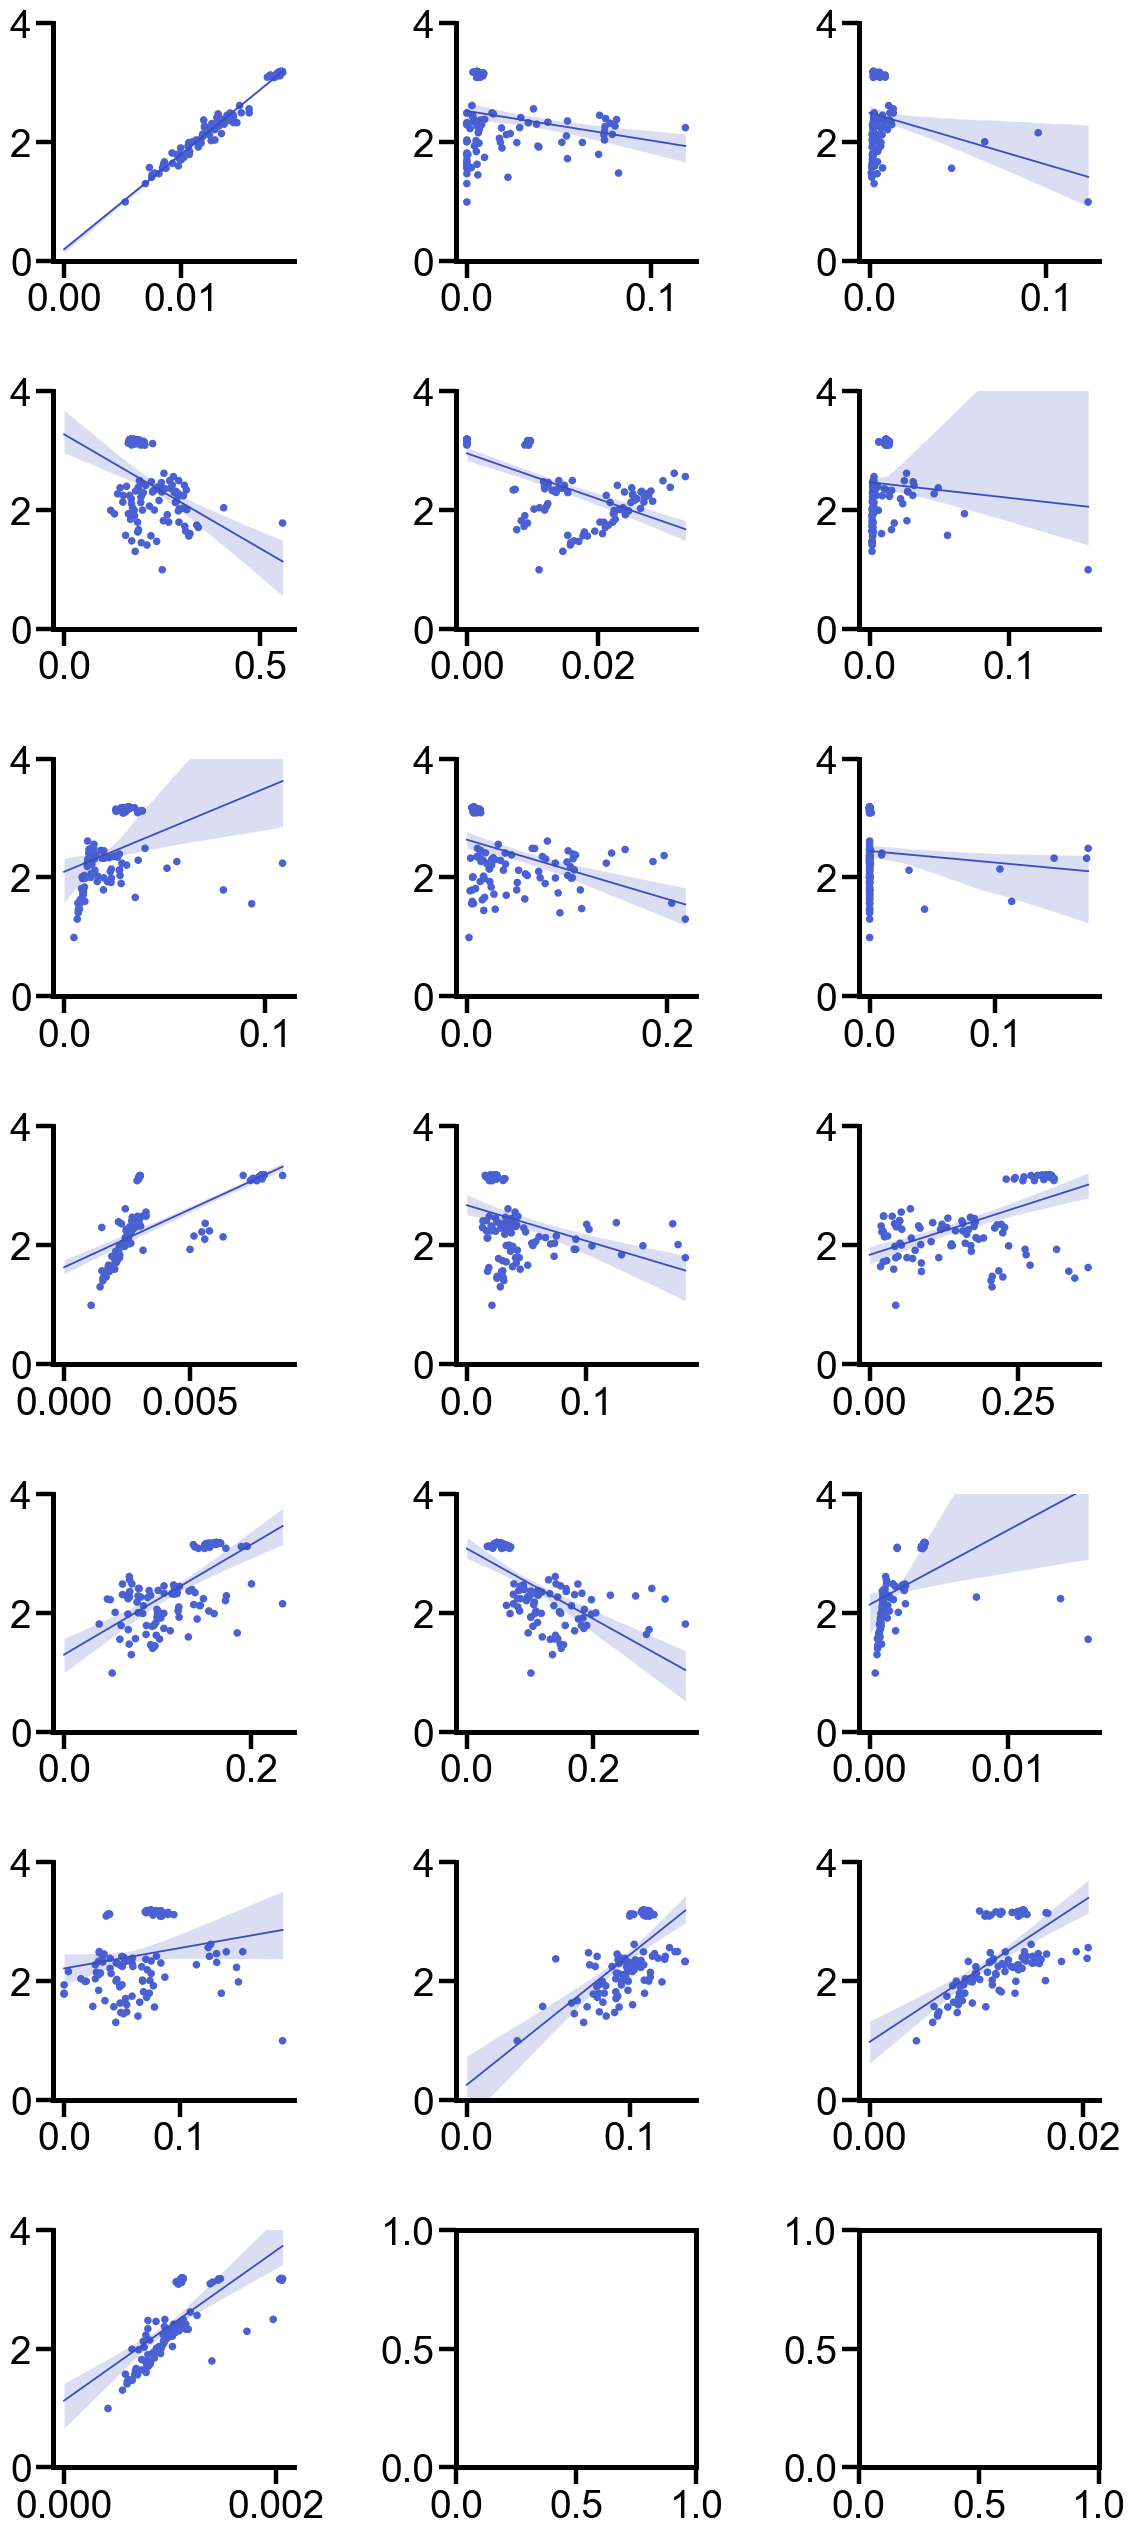

In [ ]:
set_panel_style(scale=4)
X = samples
corr_silico = []

cmap = plt.get_cmap('coolwarm')
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]
complex_line_color = colors[0]
complex_scatter_color = colors[1]


cmap = plt.get_cmap('coolwarm')
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]
complex_line_color = colors[0]
complex_scatter_color = colors[1]


corr_in_silico_complex = []

fig, axes = plt.subplots(7, 3, figsize=(12, 26))
axes = axes.flatten()  



rng = np.random.default_rng(0)

for i in range(19):

    ax = axes[i]
    x = np.array(np.array([x.E for x in X]).T[i], dtype=float)
    y = np.array(np.array([x.Y for x in X]), dtype=float)


    rho, p = spearmanr(x, y)
    print(f"Node {i}: Spearman correlation = {rho:.4f}, p-value = {p:.4e}")
    corr_in_silico_complex.append((rho, p))

    # ---------- OLS ----------
    m, b = np.polyfit(x, y, deg=1)

    xg = np.linspace(0, x.max(), 200)
    yg = m * xg + b

    # ---------- bootstrap CI ----------
    B = 2000
    n = x.size
    Yhat = np.empty((B, xg.size))

    for j in range(B):
        idx = rng.integers(0, n, n)
        m_i, b_i = np.polyfit(x[idx], y[idx], deg=1)
        Yhat[j] = m_i * xg + b_i

    lo, hi = np.percentile(Yhat, [2.5, 97.5], axis=0)

    # ---------- plot ----------
    ax.scatter(
        x, y,
        s=30,
        color=complex_scatter_color,
        edgecolors="none"
    )

    ax.plot(
        xg, yg,
        linewidth=1.3,
        color=complex_line_color
    )

    ax.fill_between(
        xg, lo, hi,
        alpha=0.18,
        color=complex_line_color,
        linewidth=0
    )

    #ax.set_xlabel(f"E_{i}")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    #ax.grid(True, alpha=0.3)

    #ax.set_xlim(0, 1.05 * x.max())
    ax.set_ylim(0, 4)


plt.tight_layout(w_pad=1.5, h_pad=1.5)
# fig.savefig(f"Supp_Figure6b.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()